# Project 1 — Predicting coronary heart disease (MICHD): the whole project in one notebook

This notebook walks through the full pipeline, from understanding the task to writing a submission file, with figures at each step.

**How to use it**
1. Put this notebook at the root of the team repository, next to `implementations.py`.
2. Unzip the dataset into a `data/` folder: `data/x_train.csv`, `data/y_train.csv`, `data/x_test.csv`.
3. Run all cells top to bottom. The first load of the CSVs takes a few minutes; after that a cache (`data/cache.npz`) makes it take seconds.

Every figure is also saved in `figures/` so it can go straight into the report.

Sections 1–13 build the first, logistic-regression pipeline step by step inside the notebook. Sections 14–19 present the second round of improvements, which live in the Python modules (`preprocessing.py`, `gradient_boosting.py`, `neural_net.py`, `cross_validation.py`); they read the cross-validation results written by `python experiments.py` to `results/`.

**Contents**
1. The project in one page
2. Loading the data
3. The labels: a strongly imbalanced problem
4. The features: missing values and types
5. Which features relate to MICHD?
6. Preprocessing pipeline
7. The 6 required methods, compared
8. Training curves
9. Choosing the decision threshold
10. Cross-validation for λ
11. Where does the model go wrong?
12. Ablation study (for the report)
13. A first submission: logistic baseline
14. Second round: rare survey modules and count features
15. Gradient-boosted trees, implemented in NumPy
16. Ensemble of networks and trees + the HAREHAB1 rule
17. Ablation study of the whole project
18. Final model and submission file (`run.py`)
19. Summary and notes for the report

Only NumPy, the standard library and matplotlib (for figures) are used, as the project rules require.

## 1. The project in one page

| | |
| --- | --- |
| **Task** | Binary classification: does a person have coronary heart disease or had a heart attack / angina (MICHD)? |
| **Data** | BRFSS 2015 telephone survey (US). Train: 328,135 people × 321 features. Test: 109,379 people. |
| **Labels** | Column `_MICHD` in `y_train.csv`, values in {-1, +1} (+1 = MICHD). |
| **Metric** | AIcrowd shows F1 and accuracy. Because only ~9% are positive, **F1 is the one that matters**. |
| **Allowed** | Python standard library, NumPy; matplotlib/seaborn for plots only. No pandas, no scikit-learn. |
| **Deliverables** | `implementations.py` (6 methods), `run.py` reproducing the best submission, `README.md`, 2-page LaTeX report. |
| **Deadline** | Oct 29, 2026, 16:00. |

The pipeline we build below:

`raw CSV → clean special codes → drop mostly-missing features → impute → standardize → model → probability → threshold → {-1, +1}`

In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt

from implementations import (
    mean_squared_error_gd,
    mean_squared_error_sgd,
    least_squares,
    ridge_regression,
    logistic_regression,
    reg_logistic_regression,
    sigmoid,
    compute_logistic_loss,
    compute_logistic_gradient,
)

DATA_PATH = "data"
FIG_PATH = "figures"
SEED = 42
os.makedirs(FIG_PATH, exist_ok=True)

plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
POS_COLOR, NEG_COLOR, ACCENT = "#d1495b", "#3d6fb6", "#edae49"


def savefig(name):
    # Save the current figure in figures/ (PDF for LaTeX) and show it.
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_PATH, name + ".pdf"))
    plt.show()

## 2. Loading the data

The CSV files contain empty fields for missing answers, which we turn into `NaN`. Parsing 105 million values in Python takes a few minutes, so the result is cached in `data/cache.npz` the first time.

Values are stored as `float32` to keep memory reasonable (~420 MB for the training set).

In [2]:
def read_csv_matrix(path, dtype=np.float32):
    # Read a numeric CSV with a header; empty fields become NaN. Returns (header, matrix).
    with open(path) as f:
        header = f.readline().rstrip("\n").split(",")
        n_rows = sum(1 for _ in f)
    out = np.empty((n_rows, len(header)), dtype=dtype)
    with open(path) as f:
        f.readline()
        for i, line in enumerate(f):
            out[i] = [float(v) if v else np.nan for v in line.rstrip("\n").split(",")]
    return header, out


def load_data(data_path=DATA_PATH):
    # Load train/test features, labels, ids and feature names, using a cache after the first call.
    cache = os.path.join(data_path, "cache.npz")
    if os.path.exists(cache):
        d = np.load(cache)
        return (d["x_train"], d["x_test"], d["y_train"], d["train_ids"], d["test_ids"],
                [str(s) for s in d["feature_names"]])
    t0 = time.time()
    header, xtr = read_csv_matrix(os.path.join(data_path, "x_train.csv"))
    _, xte = read_csv_matrix(os.path.join(data_path, "x_test.csv"))
    _, ytr = read_csv_matrix(os.path.join(data_path, "y_train.csv"), dtype=np.float64)
    train_ids, test_ids = xtr[:, 0].astype(int), xte[:, 0].astype(int)
    y_train = ytr[:, 1].astype(int)
    x_train, x_test, names = xtr[:, 1:], xte[:, 1:], header[1:]
    np.savez(cache, x_train=x_train, x_test=x_test, y_train=y_train,
             train_ids=train_ids, test_ids=test_ids, feature_names=np.array(names))
    print(f"Parsed CSVs in {time.time() - t0:.0f}s and cached them in {cache}")
    return x_train, x_test, y_train, train_ids, test_ids, names


x_train, x_test, y_train, train_ids, test_ids, feature_names = load_data()
print("x_train:", x_train.shape, " x_test:", x_test.shape, " y_train:", y_train.shape)
print("First features:", feature_names[:10])

x_train: (328135, 321)  x_test: (109379, 321)  y_train: (328135,)
First features: ['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM']


## 3. The labels: a strongly imbalanced problem

Only about 9% of people have MICHD. This one fact drives many choices:
- **Accuracy is misleading**: always answering "healthy" is ~91% accurate but finds no sick person (F1 = 0).
- **F1** balances precision (of those we flag, how many are sick) and recall (of the sick, how many we flag).
- The default threshold 0.5 on a probability will flag almost nobody; we will tune it (section 9).

MICHD (+1): 28,975 (8.8%)   healthy (-1): 299,160 (91.2%)


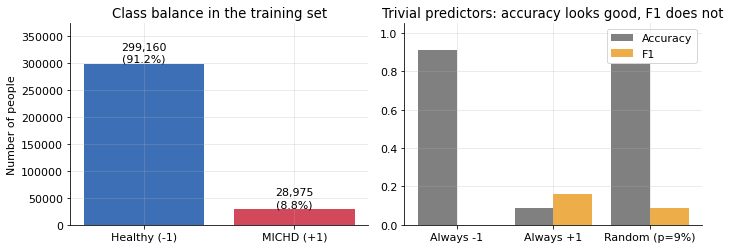

In [3]:
n_pos, n_neg = np.sum(y_train == 1), np.sum(y_train == -1)
p = n_pos / len(y_train)
print(f"MICHD (+1): {n_pos:,} ({p:.1%})   healthy (-1): {n_neg:,} ({1 - p:.1%})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(["Healthy (-1)", "MICHD (+1)"], [n_neg, n_pos], color=[NEG_COLOR, POS_COLOR])
for i, v in enumerate([n_neg, n_pos]):
    ax[0].text(i, v, f"{v:,}\n({v / len(y_train):.1%})", ha="center", va="bottom")
ax[0].set_ylabel("Number of people"); ax[0].set_title("Class balance in the training set")
ax[0].set_ylim(0, n_neg * 1.25)

# What trivial predictors score
f1_all_pos = 2 * p / (1 + p)
names_ = ["Always -1", "Always +1", f"Random (p={p:.0%})"]
acc = [1 - p, p, p * p + (1 - p) ** 2]
f1 = [0, f1_all_pos, p]
x = np.arange(3)
ax[1].bar(x - 0.2, acc, 0.4, label="Accuracy", color="grey")
ax[1].bar(x + 0.2, f1, 0.4, label="F1", color=ACCENT)
ax[1].set_xticks(x); ax[1].set_xticklabels(names_); ax[1].set_ylim(0, 1.05)
ax[1].set_title("Trivial predictors: accuracy looks good, F1 does not"); ax[1].legend()
savefig("labels_balance")

## 4. The features: missing values and types

BRFSS is a survey: many questions are only asked to some people (e.g. follow-ups), so many features are mostly empty. We look at:
1. the fraction of missing values per feature;
2. the number of distinct values, to separate binary, categorical and continuous features.

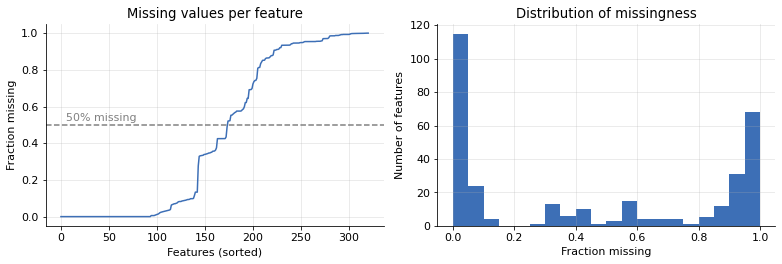

Features with more than 10% missing: 182 / 321
Features with more than 50% missing: 147 / 321
Features with more than 90% missing: 99 / 321
Rows with no missing value at all: 0.0%


In [4]:
nan_frac = np.mean(np.isnan(x_train), axis=0)
order = np.argsort(nan_frac)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(np.arange(len(nan_frac)), nan_frac[order], color=NEG_COLOR)
ax[0].axhline(0.5, ls="--", color="grey"); ax[0].text(5, 0.52, "50% missing", color="grey")
ax[0].set_xlabel("Features (sorted)"); ax[0].set_ylabel("Fraction missing")
ax[0].set_title("Missing values per feature")
ax[1].hist(nan_frac, bins=20, color=NEG_COLOR)
ax[1].set_xlabel("Fraction missing"); ax[1].set_ylabel("Number of features")
ax[1].set_title("Distribution of missingness")
savefig("missing_values")

for t in [0.1, 0.5, 0.9]:
    print(f"Features with more than {t:.0%} missing: {np.sum(nan_frac > t)} / {len(nan_frac)}")
print(f"Rows with no missing value at all: {np.mean(~np.isnan(x_train).any(axis=1)):.1%}")

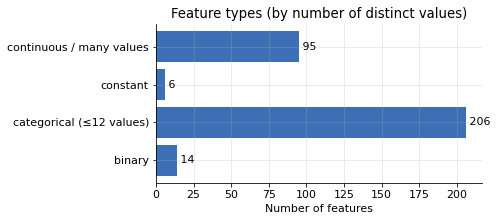

In [5]:
def n_unique(col):
    # Number of distinct non-missing values in a column.
    c = col[~np.isnan(col)]
    return len(np.unique(c))


n_uniq = np.array([n_unique(x_train[:, j]) for j in range(x_train.shape[1])])
kinds = np.where(n_uniq <= 1, "constant",
         np.where(n_uniq == 2, "binary",
         np.where(n_uniq <= 12, "categorical (≤12 values)", "continuous / many values")))
labels_k, counts_k = np.unique(kinds, return_counts=True)

plt.figure(figsize=(7, 3.2))
plt.barh(labels_k, counts_k, color=NEG_COLOR)
for i, v in enumerate(counts_k):
    plt.text(v, i, f" {v}", va="center")
plt.xlabel("Number of features"); plt.title("Feature types (by number of distinct values)")
savefig("feature_types")

### BRFSS special codes

Many answers use codes instead of values: **7 / 77 / 777 = "Don't know"**, **9 / 99 / 999 = "Refused"**, and sometimes **8 / 88 = "None"** (which is a real value, e.g. 0 days). Left as numbers, "Refused = 99" looks like a huge value to a linear model.

The cell below finds categorical features whose largest values look like these codes. Teammate B should confirm feature by feature with the [BRFSS 2015 codebook](https://www.cdc.gov/brfss/annual_data/annual_2015.html).

215 features look like they use 7/9 or 77/99 codes


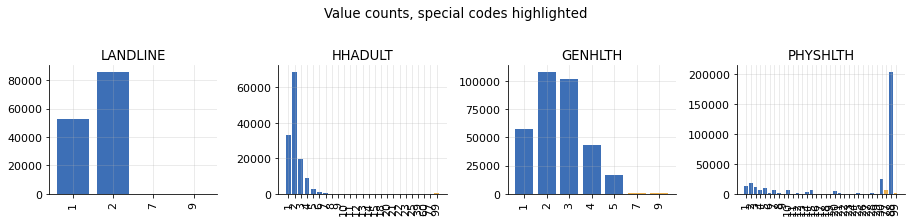

In [6]:
def code_like_features(x, n_uniq, max_levels=12):
    # Categorical features whose maximum is 9 or 99: candidates for 7/9 or 77/99 special codes.
    res = {}
    for j in range(x.shape[1]):
        if n_uniq[j] <= 2:
            continue
        m = np.nanmax(x[:, j])
        if m == 9 and n_uniq[j] <= max_levels:
            res[j] = (7, 9)
        elif m == 99:
            res[j] = (77, 99)
    return res


special = code_like_features(x_train, n_uniq)
print(f"{len(special)} features look like they use 7/9 or 77/99 codes")

# Show the value distribution of a few of them
examples = list(special)[:4]
fig, axes = plt.subplots(1, len(examples), figsize=(3.2 * len(examples), 3))
for ax, j in zip(np.atleast_1d(axes), examples):
    vals, cnt = np.unique(x_train[~np.isnan(x_train[:, j]), j], return_counts=True)
    cols = [ACCENT if v in special[j] else NEG_COLOR for v in vals]
    ax.bar([f"{v:g}" for v in vals], cnt, color=cols)
    ax.set_title(feature_names[j]); ax.tick_params(axis="x", rotation=90)
fig.suptitle("Value counts, special codes highlighted", y=1.02)
savefig("special_codes_examples")

## 5. Which features relate to MICHD?

A quick, model-free view: the correlation of each feature with the label (after median imputation), and the MICHD rate across the values of a few well-known risk factors (age, general health, sex) when they are present.

⚠️ **Check for leakage.** `_MICHD` is derived from survey questions such as `CVDINFR4` (ever told you had a heart attack) and `CVDCRHD4` (coronary heart disease). If these are among the features, they predict the label almost perfectly. Look at the top of the correlation plot and discuss it in the report.

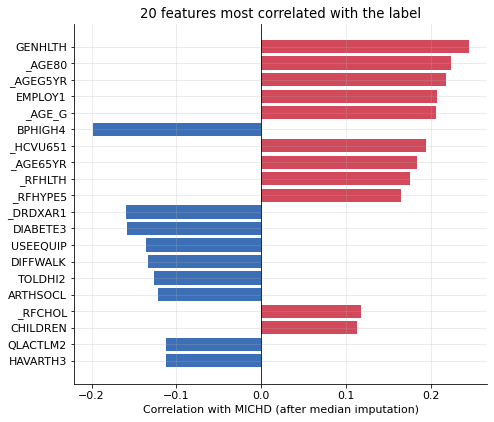

In [7]:
y01 = (y_train == 1).astype(np.float64)
# Use a random subsample of 100,000 people to keep memory low; correlations barely change.
sub = np.random.default_rng(SEED).permutation(len(y01))[:100_000]
x_imp = np.where(np.isnan(x_train[sub]), np.nanmedian(x_train[sub], axis=0), x_train[sub]).astype(np.float64)
y_sub = y01[sub]
xs = x_imp - x_imp.mean(axis=0)
std = xs.std(axis=0); std[std == 0] = np.inf
corr = (xs / std).T @ (y_sub - y_sub.mean()) / (len(y_sub) * y_sub.std())
del xs

top = np.argsort(-np.abs(corr))[:20][::-1]
plt.figure(figsize=(7, 6))
plt.barh([feature_names[j] for j in top], corr[top],
         color=[POS_COLOR if c > 0 else NEG_COLOR for c in corr[top]])
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Correlation with MICHD (after median imputation)")
plt.title("20 features most correlated with the label")
savefig("top_correlations")

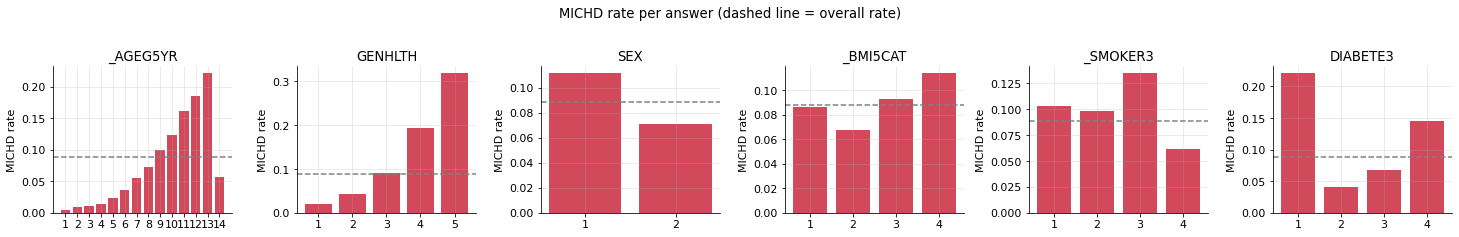

In [8]:
risk_factors = [f for f in ["_AGEG5YR", "GENHLTH", "SEX", "_BMI5CAT", "_SMOKER3", "DIABETE3"]
                if f in feature_names]
if not risk_factors:
    print("None of the usual BRFSS risk-factor names were found; pick features from the plot above.")
else:
    fig, axes = plt.subplots(1, len(risk_factors), figsize=(3.4 * len(risk_factors), 3.2), squeeze=False)
    for ax, f in zip(axes[0], risk_factors):
        j = feature_names.index(f)
        col = x_train[:, j]
        vals = np.unique(col[~np.isnan(col)])
        vals = vals[vals < 7] if np.nanmax(col) in (9, 99) and len(vals) <= 15 else vals[:15]
        rate = [y01[col == v].mean() for v in vals]
        ax.bar([f"{v:g}" for v in vals], rate, color=POS_COLOR)
        ax.axhline(y01.mean(), ls="--", color="grey")
        ax.set_title(f); ax.set_ylabel("MICHD rate")
    fig.suptitle("MICHD rate per answer (dashed line = overall rate)", y=1.02)
    savefig("risk_factors")

## 6. Preprocessing pipeline

All statistics (which columns to keep, medians, means, standard deviations) are **computed on the training data only** and then applied to validation/test data. Computing them on the test set would leak information.

Steps, each with a switch so we can measure its effect in the ablation (section 12):
1. replace special codes (7/9, 77/99) by `NaN`;
2. drop features with more than `max_nan` missing values, and constant features;
3. add a "was missing" indicator for features with some missing values (optional);
4. impute missing values with the training median;
5. standardize (zero mean, unit variance) and add a bias column of ones.

In [9]:
def fit_preprocessor(x, clean_codes=True, max_nan=0.5, missing_indicators=False):
    # Learn every preprocessing statistic from the training matrix x. Returns a dict of parameters.
    x = x.astype(np.float64)
    if clean_codes:
        x = apply_codes(x, special)
    nan_frac = np.mean(np.isnan(x), axis=0)
    std = np.nanstd(x, axis=0)
    keep = (nan_frac <= max_nan) & (std > 0)
    ind = keep & (nan_frac > 0) if missing_indicators else np.zeros_like(keep)
    med = np.nanmedian(x[:, keep], axis=0)
    xk = np.where(np.isnan(x[:, keep]), med, x[:, keep])
    if missing_indicators:
        xk = np.c_[xk, np.isnan(x[:, ind])]
    mean, sd = xk.mean(axis=0), xk.std(axis=0)
    sd[sd == 0] = 1.0
    return dict(clean_codes=clean_codes, keep=keep, ind=ind, med=med, mean=mean, sd=sd,
                missing_indicators=missing_indicators)


def apply_codes(x, codes):
    # Replace special answer codes (don't know / refused) by NaN, in place (x must be a copy).
    for j, cj in codes.items():
        x[np.isin(x[:, j], cj), j] = np.nan
    return x


def transform(x, prm):
    # Apply a fitted preprocessor to any matrix with the same columns. Returns tx with a bias column.
    x = x.astype(np.float64)
    if prm["clean_codes"]:
        x = apply_codes(x, special)
    xk = np.where(np.isnan(x[:, prm["keep"]]), prm["med"], x[:, prm["keep"]])
    if prm["missing_indicators"]:
        xk = np.c_[xk, np.isnan(x[:, prm["ind"]])]
    xk = (xk - prm["mean"]) / prm["sd"]
    return np.c_[np.ones(len(xk)), xk]


# Train / validation split (80 / 20), fixed seed
rng = np.random.default_rng(SEED)
idx = rng.permutation(len(y_train))
n_tr = int(0.8 * len(idx))
tr_idx, va_idx = idx[:n_tr], idx[n_tr:]

prm = fit_preprocessor(x_train[tr_idx])
tx_tr, tx_va = transform(x_train[tr_idx], prm), transform(x_train[va_idx], prm)
y_tr, y_va = y01[tr_idx], y01[va_idx]
print(f"Kept {prm['keep'].sum()} of {x_train.shape[1]} features -> tx has {tx_tr.shape[1]} columns")
print(f"Train: {len(y_tr):,} rows ({y_tr.mean():.1%} positive)   Validation: {len(y_va):,} rows ({y_va.mean():.1%})")

Kept 171 of 321 features -> tx has 172 columns
Train: 262,508 rows (8.8% positive)   Validation: 65,627 rows (8.9%)


## 7. The 6 required methods, compared

All six are trained on the same preprocessed training split with labels in {0, 1}. For each model we compute a score `tx @ w` (passed through the sigmoid for the logistic models) and classify with the threshold that maximises F1 on the validation set.

Note: picking the threshold on the validation set makes these numbers slightly optimistic; section 10 does it properly with cross-validation.

GD (MSE)                 loss=0.0335  val F1=0.4154  val acc=0.8667  (27.3s)
SGD (MSE)                loss=68748362.7144  val F1=0.1628  val acc=0.5154  (0.3s)
Least squares            loss=0.0333  val F1=0.4175  val acc=0.8671  (0.2s)
Ridge (λ=1e-4)           loss=0.0334  val F1=0.4160  val acc=0.8639  (0.2s)
Logistic (GD)            loss=0.2223  val F1=0.4247  val acc=0.8630  (3.9s)
Reg. logistic (λ=1e-4)   loss=0.2223  val F1=0.4245  val acc=0.8630  (3.6s)


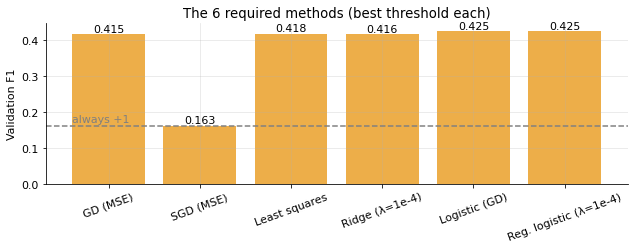

In [10]:
def f1_score(y_true, y_pred):
    # F1 score for 0/1 labels.
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    return 2 * tp / (2 * tp + fp + fn) if tp > 0 else 0.0


def best_threshold(y_true, scores, n=200):
    # Threshold on scores that maximises F1. Returns (threshold, f1).
    ts = np.quantile(scores, np.linspace(0.5, 0.995, n))
    f1s = [f1_score(y_true, (scores >= t).astype(int)) for t in ts]
    k = int(np.argmax(f1s))
    return ts[k], f1s[k]


d = tx_tr.shape[1]
w0 = np.zeros(d)
models = {
    "GD (MSE)": lambda: mean_squared_error_gd(y_tr, tx_tr, w0, 200, 0.1),
    "SGD (MSE)": lambda: mean_squared_error_sgd(y_tr, tx_tr, w0, 20000, 0.002, seed=SEED),
    "Least squares": lambda: least_squares(y_tr, tx_tr),
    "Ridge (λ=1e-4)": lambda: ridge_regression(y_tr, tx_tr, 1e-4),
    "Logistic (GD)": lambda: logistic_regression(y_tr, tx_tr, w0, 300, 0.5),
    "Reg. logistic (λ=1e-4)": lambda: reg_logistic_regression(y_tr, tx_tr, 1e-4, w0, 300, 0.5),
}

results = {}
for name, fit in models.items():
    t0 = time.time()
    try:
        w, loss = fit()
    except np.linalg.LinAlgError:
        print(f"{name}: singular matrix (collinear features) - skipped"); continue
    s = tx_va @ w
    if "ogistic" in name:
        s = sigmoid(s)
    t, f1 = best_threshold(y_va, s)
    acc = np.mean((s >= t) == y_va)
    results[name] = dict(w=w, f1=f1, acc=acc, t=t, loss=loss, secs=time.time() - t0)
    print(f"{name:24s} loss={loss:.4f}  val F1={f1:.4f}  val acc={acc:.4f}  ({time.time() - t0:.1f}s)")

names_m = list(results)
plt.figure(figsize=(9, 3.6))
plt.bar(names_m, [results[n]["f1"] for n in names_m], color=ACCENT)
for i, n in enumerate(names_m):
    plt.text(i, results[n]["f1"], f"{results[n]['f1']:.3f}", ha="center", va="bottom")
plt.axhline(f1_all_pos, ls="--", color="grey"); plt.text(-0.4, f1_all_pos + 0.01, "always +1", color="grey")
plt.ylabel("Validation F1"); plt.title("The 6 required methods (best threshold each)")
plt.xticks(rotation=20)
savefig("methods_comparison")

## 8. Training curves

How fast does gradient descent converge, and does the model overfit? We re-run logistic regression step by step (using the loss and gradient helpers from `implementations.py`) and track the loss on both the training and validation sets. If the two curves stay close, the model is not overfitting; if both are still decreasing, more iterations or a larger step size would help.

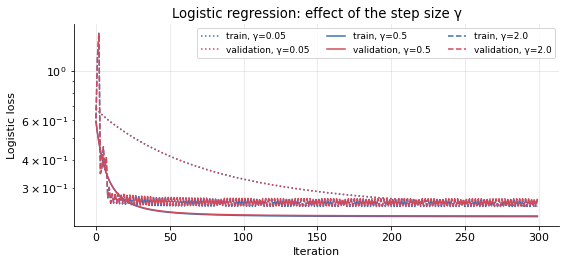

In [11]:
def logistic_curve(tx_tr, y_tr, tx_va, y_va, gamma, max_iters, lambda_=0.0):
    # Run (regularized) logistic GD and record train/validation loss at every step.
    w = np.zeros(tx_tr.shape[1]); hist_tr, hist_va = [], []
    for _ in range(max_iters):
        w = w - gamma * (compute_logistic_gradient(y_tr, tx_tr, w) + 2 * lambda_ * w)
        hist_tr.append(compute_logistic_loss(y_tr, tx_tr, w))
        hist_va.append(compute_logistic_loss(y_va, tx_va, w))
    return w, hist_tr, hist_va


plt.figure(figsize=(8, 3.8))
for gamma, ls in [(0.05, ":"), (0.5, "-"), (2.0, "--")]:
    _, htr, hva = logistic_curve(tx_tr, y_tr, tx_va, y_va, gamma, 300)
    plt.plot(htr, ls=ls, color=NEG_COLOR, label=f"train, γ={gamma}")
    plt.plot(hva, ls=ls, color=POS_COLOR, label=f"validation, γ={gamma}")
plt.xlabel("Iteration"); plt.ylabel("Logistic loss"); plt.yscale("log")
plt.title("Logistic regression: effect of the step size γ"); plt.legend(ncol=3, fontsize=9)
savefig("training_curves")

## 9. Choosing the decision threshold

A logistic model outputs a probability. With only ~9% positives these probabilities are mostly small, so the usual threshold 0.5 flags very few people and gives a poor F1. Lowering the threshold trades precision for recall; F1 peaks somewhere in between.

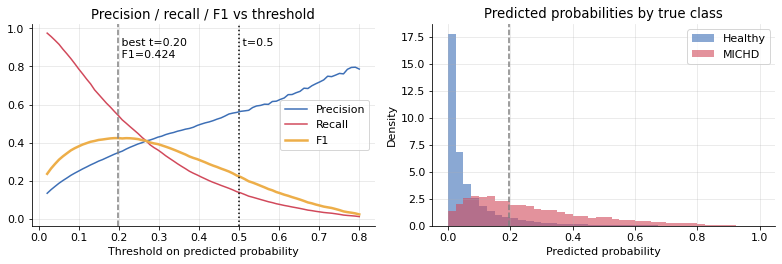

In [12]:
w_log = results["Reg. logistic (λ=1e-4)"]["w"]
prob_va = sigmoid(tx_va @ w_log)
ts = np.linspace(0.02, 0.8, 80)
prec, rec, f1s = [], [], []
for t in ts:
    pred = (prob_va >= t).astype(int)
    tp = np.sum((pred == 1) & (y_va == 1))
    prec.append(tp / max(pred.sum(), 1)); rec.append(tp / y_va.sum()); f1s.append(f1_score(y_va, pred))
t_best = ts[int(np.argmax(f1s))]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ts, prec, label="Precision", color=NEG_COLOR)
ax[0].plot(ts, rec, label="Recall", color=POS_COLOR)
ax[0].plot(ts, f1s, label="F1", color=ACCENT, lw=2.5)
ax[0].axvline(t_best, ls="--", color="grey"); ax[0].axvline(0.5, ls=":", color="black")
ax[0].text(t_best, 0.95, f" best t={t_best:.2f}\n F1={max(f1s):.3f}", va="top")
ax[0].text(0.5, 0.95, " t=0.5", va="top")
ax[0].set_xlabel("Threshold on predicted probability"); ax[0].set_title("Precision / recall / F1 vs threshold")
ax[0].legend()
bins = np.linspace(0, 1, 41)
ax[1].hist(prob_va[y_va == 0], bins=bins, alpha=0.6, density=True, color=NEG_COLOR, label="Healthy")
ax[1].hist(prob_va[y_va == 1], bins=bins, alpha=0.6, density=True, color=POS_COLOR, label="MICHD")
ax[1].axvline(t_best, ls="--", color="grey")
ax[1].set_xlabel("Predicted probability"); ax[1].set_ylabel("Density")
ax[1].set_title("Predicted probabilities by true class"); ax[1].legend()
savefig("threshold")

## 10. Cross-validation for λ

To choose the regularization strength λ fairly, we use **5-fold cross-validation** on the training split: each fold is used once as validation while the model trains on the other four. Inside each fold, the preprocessing is re-fitted on the training part only, and the threshold is chosen on that fold. We report the mean and standard deviation of F1 across folds.

On the full data this cell and the ablation take a few minutes each. To iterate faster while exploring, pass a subsample, e.g. `x_train[tr_idx[:50_000]]`.

CV done in 72s


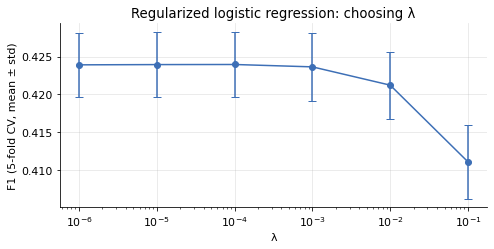

Best λ = 0.0001  (CV F1 = 0.4240 ± 0.0043)


In [13]:
def k_fold_indices(n, k, seed=SEED):
    # Shuffle 0..n-1 and split into k folds of (almost) equal size.
    return np.array_split(np.random.default_rng(seed).permutation(n), k)


def cv_reg_logistic(x, y, lambdas, k=5, max_iters=150, gamma=0.5, **prep):
    # k-fold CV of regularized logistic regression. Returns array (len(lambdas), k) of F1 scores.
    folds = k_fold_indices(len(y), k)
    scores = np.zeros((len(lambdas), k))
    for f in range(k):
        va = folds[f]; tr = np.concatenate([folds[g] for g in range(k) if g != f])
        p = fit_preprocessor(x[tr], **prep)
        ttr, tva = transform(x[tr], p), transform(x[va], p)
        for i, lam in enumerate(lambdas):
            w, _ = reg_logistic_regression(y[tr], ttr, lam, np.zeros(ttr.shape[1]), max_iters, gamma)
            scores[i, f] = best_threshold(y[va], sigmoid(tva @ w))[1]
    return scores


lambdas = np.logspace(-6, -1, 6)
t0 = time.time()
cv = cv_reg_logistic(x_train[tr_idx], y_tr, lambdas)
print(f"CV done in {time.time() - t0:.0f}s")

plt.figure(figsize=(7, 3.6))
plt.errorbar(lambdas, cv.mean(axis=1), yerr=cv.std(axis=1), marker="o", capsize=4, color=NEG_COLOR)
plt.xscale("log"); plt.xlabel("λ"); plt.ylabel("F1 (5-fold CV, mean ± std)")
plt.title("Regularized logistic regression: choosing λ")
savefig("cv_lambda")
best_lambda = lambdas[int(np.argmax(cv.mean(axis=1)))]
print(f"Best λ = {best_lambda:g}  (CV F1 = {cv.mean(axis=1).max():.4f} ± {cv.std(axis=1)[np.argmax(cv.mean(axis=1))]:.4f})")

## 11. Where does the model go wrong?

The confusion matrix shows the four outcomes on the validation set. With an imbalanced problem, false positives (healthy people flagged) and false negatives (missed MICHD cases) behave very differently. Looking at the largest weights tells us which features drive the predictions.

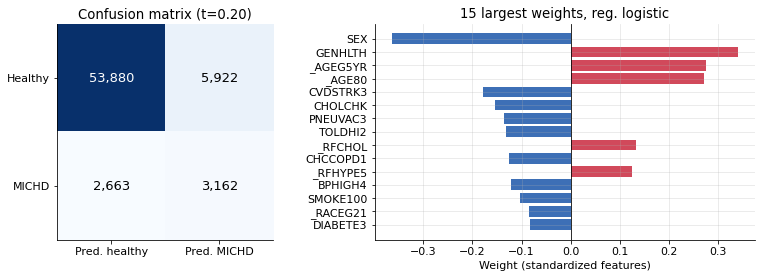

In [14]:
pred_va = (prob_va >= t_best).astype(int)
cm = np.array([[np.sum((y_va == a) & (pred_va == b)) for b in (0, 1)] for a in (0, 1)])

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].imshow(cm, cmap="Blues"); ax[0].grid(False)
for a in range(2):
    for b in range(2):
        ax[0].text(b, a, f"{cm[a, b]:,}", ha="center", va="center",
                   color="white" if cm[a, b] > cm.max() / 2 else "black", fontsize=13)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Pred. healthy", "Pred. MICHD"])
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["Healthy", "MICHD"])
ax[0].set_title(f"Confusion matrix (t={t_best:.2f})")

kept_names = [n for n, k in zip(feature_names, prm["keep"]) if k]
wf = w_log[1:len(kept_names) + 1]
topw = np.argsort(-np.abs(wf))[:15][::-1]
ax[1].barh([kept_names[j] for j in topw], wf[topw], color=[POS_COLOR if v > 0 else NEG_COLOR for v in wf[topw]])
ax[1].axvline(0, color="black", lw=0.8)
ax[1].set_xlabel("Weight (standardized features)"); ax[1].set_title("15 largest weights, reg. logistic")
savefig("errors_and_weights")

## 12. Ablation study (for the report)

The report is graded partly on *solid baselines and an ablation*: showing how much each modification changes the score. Each row below changes one thing relative to the previous one, and is evaluated with the same 5-fold CV.

Add a row every time the team tries a new idea (one-hot encoding, class weights, feature expansion, …). This figure and the table can go directly into the report.

Baseline: no code cleaning, max_nan=1.0       F1 = 0.4151 ± 0.0033
+ drop features >50% missing                  F1 = 0.4105 ± 0.0025
+ special codes -> NaN                        F1 = 0.4240 ± 0.0043
+ missing-value indicators                    F1 = 0.4244 ± 0.0041


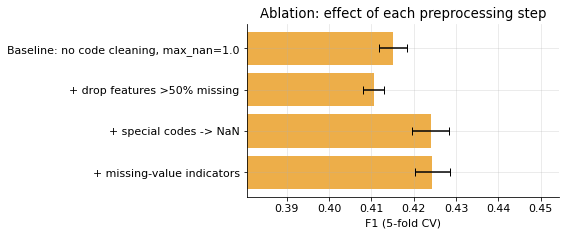

In [15]:
ablation = [
    ("Baseline: no code cleaning, max_nan=1.0", dict(clean_codes=False, max_nan=1.0)),
    ("+ drop features >50% missing", dict(clean_codes=False, max_nan=0.5)),
    ("+ special codes -> NaN", dict(clean_codes=True, max_nan=0.5)),
    ("+ missing-value indicators", dict(clean_codes=True, max_nan=0.5, missing_indicators=True)),
]
abl = []
for label, prep in ablation:
    s = cv_reg_logistic(x_train[tr_idx], y_tr, [best_lambda], **prep)[0]
    abl.append((label, s.mean(), s.std()))
    print(f"{label:45s} F1 = {s.mean():.4f} ± {s.std():.4f}")

plt.figure(figsize=(8, 3.4))
yy = np.arange(len(abl))[::-1]
plt.barh(yy, [a[1] for a in abl], xerr=[a[2] for a in abl], color=ACCENT, capsize=4)
plt.yticks(yy, [a[0] for a in abl])
lo = min(a[1] for a in abl) - 0.03
plt.xlim(max(lo, 0), max(a[1] for a in abl) + 0.03)
plt.xlabel("F1 (5-fold CV)"); plt.title("Ablation: effect of each preprocessing step")
savefig("ablation_logistic_preprocessing")

## 13. A first submission: logistic baseline

We retrain the chosen logistic model on **all** the training data, choose the threshold on a held-out 20% first, and write predictions in the AIcrowd format (`Id,Prediction` with values in {-1, +1}).

This was our first submission. It is written to `submission_baseline.csv` so that it does not overwrite the final `submission.csv`, which is produced by `run.py` (section 18).

In [16]:
# 1) choose the threshold with the train/validation split
best_cfg = dict(clean_codes=True, max_nan=0.5)
p_tmp = fit_preprocessor(x_train[tr_idx], **best_cfg)
w_tmp, _ = reg_logistic_regression(y_tr, transform(x_train[tr_idx], p_tmp), best_lambda,
                                   np.zeros(p_tmp["keep"].sum() + 1), 300, 0.5)
t_final, f1_final = best_threshold(y_va, sigmoid(transform(x_train[va_idx], p_tmp) @ w_tmp))
print(f"Validation F1 = {f1_final:.4f} at threshold {t_final:.3f}")

# 2) retrain on all training data and predict the test set
p_all = fit_preprocessor(x_train, **best_cfg)
tx_all, tx_test = transform(x_train, p_all), transform(x_test, p_all)
w_final, _ = reg_logistic_regression(y01, tx_all, best_lambda, np.zeros(tx_all.shape[1]), 300, 0.5)
y_pred = np.where(sigmoid(tx_test @ w_final) >= t_final, 1, -1)


def write_submission(ids, y_pred, path):
    # Write predictions in the AIcrowd format: header 'Id,Prediction', one row per test id.
    with open(path, "w") as f:
        f.write("Id,Prediction\n")
        for i, p in zip(ids, y_pred):
            f.write(f"{int(i)},{int(p)}\n")


write_submission(test_ids, y_pred, "submission_baseline.csv")
print(f"submission_baseline.csv: {len(y_pred):,} rows, {np.mean(y_pred == 1):.1%} predicted MICHD "
      f"(training rate: {y01.mean():.1%})")

Validation F1 = 0.4245 at threshold 0.186
submission_baseline.csv: 109,379 rows, 14.8% predicted MICHD (training rate: 8.8%)


## 14. Second round: rare survey modules and count features

After the first round (sections 1–13, then the one-hot pipeline and the neural networks of `preprocessing.py` / `neural_net.py`), the remaining gains came from looking again at **what the survey asks to whom**.

BRFSS has a core questionnaire asked to everybody, plus **optional modules** that only some states use, and **skip logic**: follow-up questions are only asked after certain answers. Our preprocessing dropped every column missing for more than 99% of people. That removed 30 questions, among them:

* `HAREHAB1` — *"Following your heart attack, did you go to any kind of outpatient rehabilitation?"* It is only asked to people who reported a heart attack, so **everybody who answered it has MICHD** (773 of 773 in the training set, 238 such people in the test set).
* `STREHAB1` (rehabilitation after a stroke), the asthma call-back module (`AS*`), the cognitive-decline module (`CDHELP`), the prostate-cancer screening module (`PCPS*`, `PSATIME`)… whose answers come with MICHD rates far from the 8.8% average.

The cell below lists them. Keeping them (`max_nan=1.0`) only adds a few one-hot columns ("answered X") and costs nothing.

30 columns are missing for more than 99% of people (dropped by the first pipeline)
feature    answered   MICHD rate when answered
HAREHAB1        773                     100.0%
STREHAB1        517                      35.8%
CDHELP         3084                      28.7%
ASNOSLEP        342                      20.2%
ASERVIST        228                      19.3%
ASDRVIST        228                      19.3%
PCDMDECN        179                      17.9%
ASRCHKUP        487                      17.0%
ASACTLIM        487                      17.0%
ASATTACK        490                      16.9%
ASINHALR        485                      16.9%
ASTHMED3        485                      16.9%


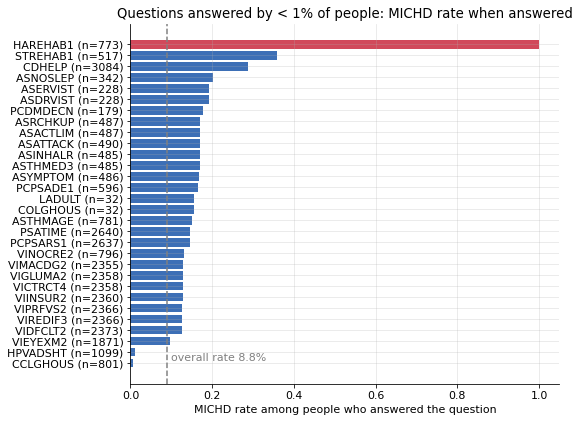

In [17]:
import json
from preprocessing import engineered_features, ENGINEERED

y01 = (y_train == 1).astype(np.float64)
nan_frac = np.mean(np.isnan(x_train), axis=0)
rare = [j for j in np.flatnonzero(nan_frac > 0.99)]
answered = np.array([np.sum(~np.isnan(x_train[:, j])) for j in rare])
rate = np.array([y01[~np.isnan(x_train[:, j])].mean() for j in rare])
order = np.argsort(rate)
print(f"{len(rare)} columns are missing for more than 99% of people (dropped by the first pipeline)")
print(f"{'feature':10s} {'answered':>8s} {'MICHD rate when answered':>26s}")
for k in order[::-1][:12]:
    print(f"{feature_names[rare[k]]:10s} {answered[k]:8d} {rate[k]:26.1%}")

plt.figure(figsize=(8, 6))
cols = [POS_COLOR if feature_names[rare[k]] == "HAREHAB1" else NEG_COLOR for k in order]
plt.barh([f"{feature_names[rare[k]]} (n={answered[k]})" for k in order], rate[order], color=cols)
plt.axvline(y01.mean(), ls="--", color="grey"); plt.text(y01.mean() + 0.01, 0.2, "overall rate 8.8%", color="grey")
plt.xlabel("MICHD rate among people who answered the question")
plt.title("Questions answered by < 1% of people: MICHD rate when answered")
savefig("rare_modules")

### Count features

A linear model can only *add* the effects of one-hot columns, and a tree needs many splits to *count*. We add three summaries (`preprocessing.engineered_features`):

* `n_chronic`: number of chronic conditions answered "yes" (stroke, asthma, skin / other cancer, COPD, arthritis, depression, kidney disease, diabetes, high cholesterol, high blood pressure);
* `n_disabilities`: number of activity limitations / difficulties (walking, dressing, errands, vision, memory, special equipment, limited activity);
* `n_missing`: number of unanswered questions (it reflects the skip logic, i.e. what the person answered before, and the optional modules of the state).

For logistic regression they make no measurable difference (rows 8 → 9 of the ablation), as expected since it can already add up the one-hot columns; they matter for the trees, where `n_chronic` and `n_missing` are among the most used features (section 15). The MICHD rate grows steadily with the number of chronic conditions:

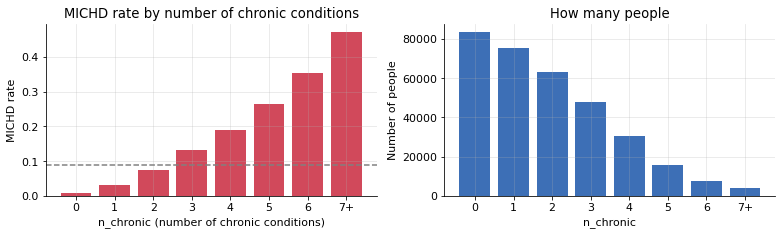

In [18]:
eng = engineered_features(x_train, feature_names)
n_chronic = eng[:, ENGINEERED.index("n_chronic")].astype(int)
levels = np.arange(0, 8)
rate_c = [y01[np.minimum(n_chronic, 7) == v].mean() for v in levels]
count_c = [np.sum(np.minimum(n_chronic, 7) == v) for v in levels]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar([str(v) if v < 7 else "7+" for v in levels], rate_c, color=POS_COLOR)
ax[0].axhline(y01.mean(), ls="--", color="grey")
ax[0].set_xlabel("n_chronic (number of chronic conditions)"); ax[0].set_ylabel("MICHD rate")
ax[0].set_title("MICHD rate by number of chronic conditions")
ax[1].bar([str(v) if v < 7 else "7+" for v in levels], count_c, color=NEG_COLOR)
ax[1].set_xlabel("n_chronic"); ax[1].set_ylabel("Number of people"); ax[1].set_title("How many people")
savefig("n_chronic")

## 15. Gradient-boosted trees, implemented in NumPy

Our strongest single model is a from-scratch **gradient-boosted decision tree** ensemble (`gradient_boosting.py`, NumPy only), built like XGBoost / LightGBM:

1. **Binning.** Each feature is cut once into at most 64 bins (one per value for categorical answers, quantiles for continuous ones). Missing values get their own bin, so trees need **no imputation, no one-hot encoding and no scaling** — they get the raw survey codes (`preprocessing.tree_features`).
2. **Newton boosting.** Starting from the base rate, each new tree is fitted to the gradient $g_i = p_i - y_i$ and hessian $h_i = p_i(1-p_i)$ of the logistic loss at the current predictions. A leaf with gradient sum $G$ and hessian sum $H$ gets the value $-G/(H+\lambda)$ (times the learning rate 0.03).
3. **Histogram split search.** For a node, the sums of $g$ and $h$ per bin are accumulated with `np.bincount`; every threshold of every feature is then scored at once by the gain $\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{G^2}{H+\lambda}$. Missing values are sent to the side with the larger gain. Only the smaller child's histogram is computed; the other is *parent − smaller child*.
4. **Regularization.** Depth ≤ 6, minimum hessian 10 per child, $\lambda = 10$, each tree sees a random 70% of the rows and 40% of the features; 1000 trees.

We first tried learning rate 0.05, minimum hessian 5, $\lambda=5$ and 50% of the features: its out-of-fold F1 peaked at 0.4466 around 450 trees and then decreased (0.4449 at 800 trees). The slower, more regularized setting above reaches the same level and then stays flat, which makes the number of trees uncritical.

A small demonstration on a subsample (the full model is trained by `experiments.py` / `run.py`):

Tree features: 288 raw columns (NaN kept), no one-hot / imputation / scaling
200 trees on 60,000 people in 25s


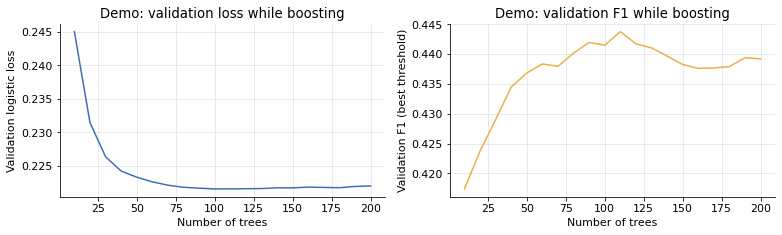

In [19]:
from gradient_boosting import GBDT
from preprocessing import fit_tree_features, tree_features

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(y01))
demo_tr, demo_va = perm[:60_000], perm[60_000:100_000]
tprm = fit_tree_features(x_train[demo_tr], feature_names)
f_tr, f_va = tree_features(x_train[demo_tr], tprm), tree_features(x_train[demo_va], tprm)
print(f"Tree features: {f_tr.shape[1]} raw columns (NaN kept), no one-hot / imputation / scaling")
t0 = time.time()
demo = GBDT(n_trees=200, learning_rate=0.1, max_depth=5, seed=0).fit(f_tr, y01[demo_tr], x_eval=f_va, eval_every=10)
print(f"200 trees on 60,000 people in {time.time() - t0:.0f}s")
steps = sorted(demo.staged_eval)
logloss = lambda y, p: np.mean(-y * np.log(p) - (1 - y) * np.log(1 - p))
va_loss = [logloss(y01[demo_va], demo.staged_eval[s]) for s in steps]
va_f1 = [best_threshold(y01[demo_va], demo.staged_eval[s])[1] for s in steps]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(steps, va_loss, color=NEG_COLOR); ax[0].set_xlabel("Number of trees"); ax[0].set_ylabel("Validation logistic loss")
ax[0].set_title("Demo: validation loss while boosting")
ax[1].plot(steps, va_f1, color=ACCENT); ax[1].set_xlabel("Number of trees"); ax[1].set_ylabel("Validation F1 (best threshold)")
ax[1].set_title("Demo: validation F1 while boosting")
savefig("gbdt_demo")

With the large learning rate of this demo (0.1) and only 60,000 people, the validation loss stops improving after ~100 trees and the F1 then decreases: boosting overfits when it runs too long, so the number of trees has to be chosen on validation data. This is why the full model uses a smaller learning rate (0.03) and stronger regularization.

On the full data, with 5-fold cross-validation (`python experiments.py ablation 13`), the out-of-fold F1 rises quickly up to ~450 trees and then stays flat up to 1000 trees. On the right, the features used in the most splits. Split counts favour continuous features (BMI, weight, fitness, fruit and vegetable intake), which offer many thresholds; the main risk factors (age, general health, diabetes age, physical health) and our count features `n_chronic` and `n_missing` are also among the most used:

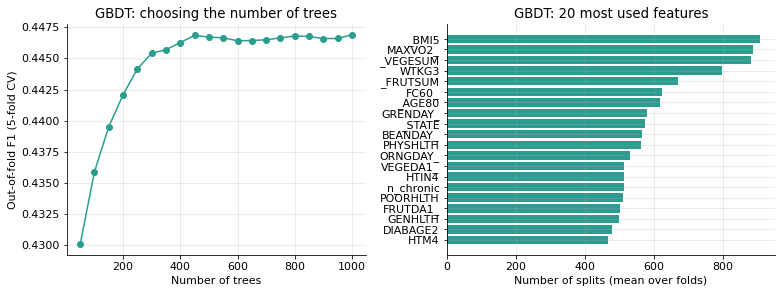

Out-of-fold F1 by number of trees: {50: 0.43, 150: 0.4395, 250: 0.4442, 350: 0.4457, 450: 0.4469, 550: 0.4467, 650: 0.4464, 750: 0.4467, 850: 0.4468, 950: 0.4466}


In [20]:
results = json.load(open("results/results.json"))
st = results["gbdt_trees"]
n_trees = sorted(int(k) for k in st)
imp = results["gbdt_importance"]
top = sorted(imp, key=lambda c: -imp[c])[:20][::-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
ax[0].plot(n_trees, [st[str(k)] for k in n_trees], marker="o", color="#2a9d8f")
ax[0].set_xlabel("Number of trees"); ax[0].set_ylabel("Out-of-fold F1 (5-fold CV)")
ax[0].set_title("GBDT: choosing the number of trees")
ax[1].barh(top, [imp[c] for c in top], color="#2a9d8f")
ax[1].set_xlabel("Number of splits (mean over folds)"); ax[1].set_title("GBDT: 20 most used features")
savefig("gbdt_cv")
print("Out-of-fold F1 by number of trees:", {k: round(st[str(k)], 4) for k in n_trees[::2]})

## 16. Ensemble of networks and trees + the HAREHAB1 rule

The networks and the trees make different kinds of errors: the networks learn smooth functions of the standardized one-hot features, the trees learn sharp thresholds and interactions on the raw codes. Averaging their **log-odds** (`cross_validation.combine`) with weights chosen on the out-of-fold predictions (`python experiments.py weights`, grid with step 0.05) is better than each of them. Adding the logistic regression as a third member got a weight of about 0 in that search, so the final ensemble has two members.

Finally, the **HAREHAB1 rule** sets the probability to 1 for the people who answered `HAREHAB1`. With the rare module questions in the features the models already flag nearly all of them, so the rule changes almost nothing in cross-validation, but it guarantees that these 238 test respondents are predicted positive. In the report this must be stated clearly: it is not a medical finding but a consequence of the survey's skip logic.

Logistic (Newton)            OOF F1 = 0.4390   per-fold F1 = 0.4399 ± 0.0009   acc = 0.8770   t = 0.205
5 networks (wide)            OOF F1 = 0.4451   per-fold F1 = 0.4457 ± 0.0021   acc = 0.8808   t = 0.215
GBDT                         OOF F1 = 0.4469   per-fold F1 = 0.4476 ± 0.0021   acc = 0.8788   t = 0.215
Ensemble                     OOF F1 = 0.4476   per-fold F1 = 0.4489 ± 0.0014   acc = 0.8760   t = 0.205
Ensemble + HAREHAB1 rule     OOF F1 = 0.4476   per-fold F1 = 0.4489 ± 0.0014   acc = 0.8760   t = 0.205

Best ensemble weights on the out-of-fold predictions, members: ['wider networks, cosine LR decay', 'Gradient-boosted trees (NumPy)', 'Newton solver, lambda=1e-4 (logistic)']
   [0.3, 0.7, 0.0]  ->  OOF F1 = 0.4481
   [0.5, 0.5, 0.0]  ->  OOF F1 = 0.4480
   [0.25, 0.75, 0.0]  ->  OOF F1 = 0.4479
   [0.35, 0.65, 0.0]  ->  OOF F1 = 0.4478
   [0.15, 0.85, 0.0]  ->  OOF F1 = 0.4478

People who answered HAREHAB1: 773; flagged by the ensemble before the rule: 100.0%
(the first fina

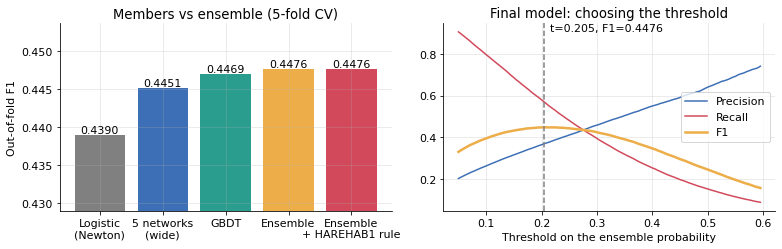

In [21]:
from cross_validation import combine, apply_rehab_rule
from experiments import ABLATION, ENSEMBLE, LOGISTIC_NEWTON, oof_path

rows = results["ablation"]
row_of = lambda cfg: next(i for i, (_, c) in enumerate(ABLATION) if c == cfg)
final_row = len(ABLATION) - 1
show = [row_of(LOGISTIC_NEWTON)] + [row_of(m) for m in ENSEMBLE["members"]] + [final_row - 1, final_row]
names_show = ["Logistic\n(Newton)", "5 networks\n(wide)", "GBDT", "Ensemble", "Ensemble\n+ HAREHAB1 rule"]
f1_show = [rows[i]["oof_f1"] for i in show]
for nm, i in zip(names_show, show):
    r = rows[i]
    print(f"{nm.replace(chr(10), ' '):28s} OOF F1 = {r['oof_f1']:.4f}   per-fold F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   acc = {r['oof_acc']:.4f}   t = {r['threshold']:.3f}")
print("\nBest ensemble weights on the out-of-fold predictions, members:", results["weights"]["members"])
for g in results["weights"]["grid"][:5]:
    print(f"   {g['weights']}  ->  OOF F1 = {g['f1']:.4f}")

oof_final = np.load(oof_path(final_row)).astype(np.float64)
oof_ens = np.load(oof_path(final_row - 1)).astype(np.float64)
hare = ~np.isnan(x_train[:, feature_names.index("HAREHAB1")])
t_ens = rows[final_row - 1]["threshold"]
print(f"\nPeople who answered HAREHAB1: {hare.sum()}; flagged by the ensemble before the rule: {np.mean(oof_ens[hare] >= t_ens):.1%}")
old = np.load(oof_path(6)).astype(np.float64)  # first final model (5 networks, old features)
print(f"(the first final model, row 6, flagged only {np.mean(old[hare] >= rows[6]['threshold']):.1%} of them)")

ts = np.arange(0.05, 0.6, 0.005)
prec, rec, f1s = [], [], []
for t in ts:
    pred = (oof_final >= t).astype(int); tp = np.sum((pred == 1) & (y01 == 1))
    prec.append(tp / max(pred.sum(), 1)); rec.append(tp / y01.sum()); f1s.append(f1_score(y01, pred))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(names_show, f1_show, color=["grey", NEG_COLOR, "#2a9d8f", ACCENT, POS_COLOR])
for k, v in enumerate(f1_show):
    ax[0].text(k, v, f"{v:.4f}", ha="center", va="bottom")
ax[0].set_ylim(min(f1_show) - 0.01, max(f1_show) + 0.006); ax[0].set_ylabel("Out-of-fold F1")
ax[0].set_title("Members vs ensemble (5-fold CV)")
ax[1].plot(ts, prec, label="Precision", color=NEG_COLOR); ax[1].plot(ts, rec, label="Recall", color=POS_COLOR)
ax[1].plot(ts, f1s, label="F1", color=ACCENT, lw=2.5)
t_best = rows[final_row]["threshold"]; ax[1].axvline(t_best, ls="--", color="grey")
ax[1].text(t_best + 0.01, 0.95, f"t={t_best:.3f}, F1={rows[final_row]['oof_f1']:.4f}", va="top")
ax[1].set_xlabel("Threshold on the ensemble probability"); ax[1].set_title("Final model: choosing the threshold")
ax[1].legend(loc="center right")
savefig("ensemble")

### Leakage check

How much of the improvement comes from `HAREHAB1` alone? `python experiments.py leakage` repeats the two final models and their ensemble with the column removed everywhere (also from the `n_missing` count). The difference between the final model and its leakage-free version is the part of the score that comes from the skip logic; the difference between the leakage-free version and the previous submission (row 6, which did not see the column either) is the part that comes from all other changes (models and other features).

In [22]:
leak = json.load(open("results/results.json"))["leakage"]
for r in leak:
    print(f"{r['label']:34s} OOF F1 = {r['oof_f1']:.4f}   per-fold F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   acc = {r['oof_acc']:.4f}")
prev, final, no_leak = rows[6]["oof_f1"], rows[final_row]["oof_f1"], leak[2]["oof_f1"]
print(f"\nGain of the final model over the previous submission (row 6): {final - prev:+.4f} OOF F1")
print(f"  from all other changes (leakage-free ensemble vs row 6): {no_leak - prev:+.4f}")
print(f"  from the HAREHAB1 column (final vs leakage-free):     {final - no_leak:+.4f}")

Wider networks without HAREHAB1    OOF F1 = 0.4366   per-fold F1 = 0.4368 ± 0.0012   acc = 0.8778
GBDT without HAREHAB1              OOF F1 = 0.4378   per-fold F1 = 0.4384 ± 0.0024   acc = 0.8817
Ensemble without HAREHAB1          OOF F1 = 0.4392   per-fold F1 = 0.4399 ± 0.0018   acc = 0.8796

Gain of the final model over the previous submission (row 6): +0.0138 OOF F1
  from all other changes (leakage-free ensemble vs row 6): +0.0053
  from the HAREHAB1 column (final vs leakage-free):     +0.0084


## 17. Ablation study of the whole project

Every row is evaluated with the same 5 folds; the preprocessing is re-fitted inside each fold. Blue: first preprocessing steps (logistic regression); orange: the first final models; green: the second round. "OOF F1" is the F1 of all out-of-fold probabilities at one global threshold (the number that best predicts the test score, since the submission also uses one threshold); "fold F1" is the mean ± std over folds of the F1 at each fold's own best threshold.

   configuration                                       fold F1   OOF F1     acc      t
0  Raw features (median imputation)           0.4161 ± 0.0014   0.4155  0.8690  0.205
1  + drop admin. / duplicate columns          0.4161 ± 0.0019   0.4154  0.8715  0.210
2  + clean special & frequency codes, log     0.4177 ± 0.0011   0.4173  0.8698  0.205
3  + one-hot categorical features             0.4326 ± 0.0014   0.4317  0.8647  0.185
4  + age / health interactions                0.4323 ± 0.0016   0.4313  0.8674  0.190
5    class weights (positives x3)             0.4322 ± 0.0016   0.4312  0.8671  0.415
6  Ensemble of 5 neural networks              0.4343 ± 0.0021   0.4339  0.8795  0.215
7  Blend: logistic + 5 networks               0.4335 ± 0.0016   0.4330  0.8745  0.205
8  + keep rare module questions (logistic)    0.4406 ± 0.0014   0.4395  0.8755  0.200
9  + count features (logistic)                0.4406 ± 0.0012   0.4395  0.8755  0.200
10   Newton solver, lambda=1e-4 (logistic)    0.4399 

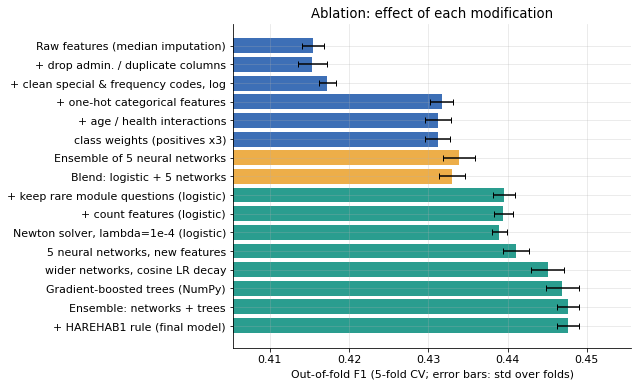

In [23]:
print(f"{'':3s}{'configuration':42s} {'fold F1':>16s} {'OOF F1':>8s} {'acc':>7s} {'t':>6s}")
for i, r in enumerate(rows):
    print(f"{i:<3d}{r['label']:42s} {r['f1_mean']:.4f} ± {r['f1_std']:.4f} {r['oof_f1']:8.4f} {r['oof_acc']:7.4f} {r['threshold']:6.3f}")

colors = ["#3d6fb6" if i < 6 else ACCENT if i < 8 else "#2a9d8f" for i in range(len(rows))]
plt.figure(figsize=(9, 5.5))
yy = np.arange(len(rows))[::-1]
plt.barh(yy, [r["oof_f1"] for r in rows], xerr=[r["f1_std"] for r in rows], color=colors, capsize=3)
plt.yticks(yy, [r["label"].strip() for r in rows])
lo = min(r["oof_f1"] for r in rows)
plt.xlim(lo - 0.01, max(r["oof_f1"] for r in rows) + 0.008)
plt.xlabel("Out-of-fold F1 (5-fold CV; error bars: std over folds)")
plt.title("Ablation: effect of each modification")
savefig("ablation")

## 18. Final model and submission file (`run.py`)

`run.py` trains the final ensemble on **all** training rows and writes `submission.csv`:

1. one-hot design matrix with the rare module questions and count features → 5 neural networks (128 hidden units, 6 epochs, cosine learning-rate decay, seeds 0–4);
2. raw columns → GBDT (NumPy, see section 15);
3. weighted average of the two log-odds, then the HAREHAB1 rule;
4. threshold chosen on the out-of-fold predictions of the same pipeline (section 16).

All seeds are fixed, so running it again gives the same file. It takes about 10–15 minutes on a laptop; set `RUN_FINAL = False` to skip it here.

In [24]:
RUN_FINAL = True
if RUN_FINAL:
    import run
    t0 = time.time()
    run.main()
    print(f"run.py finished in {(time.time() - t0) / 60:.1f} min")
sub = np.genfromtxt("submission.csv", delimiter=",", skip_header=1, dtype=int)
print(f"submission.csv: {len(sub):,} rows, ids {sub[0, 0]}..{sub[-1, 0]}, {np.mean(sub[:, 1] == 1):.1%} predicted MICHD")

Train (328135, 321), test (109379, 321), positives 8.8%
Wrote submission.csv: 109,379 rows, 13.8% predicted MICHD (threshold 0.205) in 10.6 min
run.py finished in 10.6 min
submission.csv: 109,379 rows, ids 328135..437513, 13.8% predicted MICHD


## 19. Summary and notes for the report

**What improved the cross-validated F1** (rows of the ablation, section 17):

* *Keeping the rare optional-module questions* was the largest single gain of the second round. Most of it comes from `HAREHAB1`: the first final model (row 6) flagged only ~62% of the people who answered it, the new models flag all of them.
* *Gradient-boosted trees* (implemented from scratch) are the best single model; they need no imputation or encoding and learn interactions on their own.
* *Wider networks trained longer with a cosine learning-rate decay* (128 units, 6 epochs) improve the networks by about +0.004.
* *Averaging networks and trees* in log-odds space adds a little more; the per-fold F1 also becomes more stable (smaller std).

**What did not help** (useful for the discussion): Newton's method instead of gradient descent for logistic regression (same F1, the GD solution was already good enough for thresholding); adding the logistic regression to the ensemble (weight ≈ 0 in the grid search); even larger networks (256 units, 8 epochs: no better than 128); a "state used the rehabilitation module" indicator (the trees were already calibrated for those people); class weights (row 5).

**To state in the report:**
* the HAREHAB1 rule and the gain from rare module questions come from the survey's skip logic (label leakage through question routing), not from medical risk factors — legitimate for the competition since these answers are in the test features, but not a clinical finding;
* the leakage check (section 16) quantifies it: of the +0.014 OOF F1 gained over the previous submission, +0.008 comes from the `HAREHAB1` column alone and +0.005 from all other changes;
* the decision threshold (0.205) and the ensemble weights were chosen on out-of-fold predictions, never on the test set;
* `run.py` reproduces `submission.csv` exactly (fixed seeds); its cross-validated F1 is in the table below.

In [25]:
first, final = rows[6], rows[final_row]
print(f"Previous submission (row 6, 5 networks):  OOF F1 = {first['oof_f1']:.4f}, per-fold F1 = {first['f1_mean']:.4f} ± {first['f1_std']:.4f}, acc = {first['oof_acc']:.4f}")
print(f"Final model (row {final_row}):                   OOF F1 = {final['oof_f1']:.4f}, per-fold F1 = {final['f1_mean']:.4f} ± {final['f1_std']:.4f}, acc = {final['oof_acc']:.4f}")
print(f"Gain in out-of-fold F1: {final['oof_f1'] - first['oof_f1']:+.4f}")

Previous submission (row 6, 5 networks):  OOF F1 = 0.4339, per-fold F1 = 0.4343 ± 0.0021, acc = 0.8795
Final model (row 15):                   OOF F1 = 0.4476, per-fold F1 = 0.4489 ± 0.0014, acc = 0.8760
Gain in out-of-fold F1: +0.0138
